![Banner](../images/03_04_banner_spatial_analysis_Multi_Criteria.png)




# Weighted Suitability Analysis

This notebook demonstrates how to perform a weighted suitability analysis, a method for combining multiple spatial criteria, such as healthcare need, capacity, rurality, and access, into a single county-level score to guide resource prioritization in New York State.

## Overview

Weighted suitability analysis is a powerful spatial decision-making method used when multiple criteria must be considered to identify optimal locations for interventions or resources.

In this notebook, we illustrate how to synthesize a range of county-level indicators, such as healthcare need, ICU capacity, rurality, and access to critical care hubs, into a single composite suitability score for each county in New York State.

This approach enables us to:
- Standardize factors measured on different scales, making them directly comparable
- Assign different weights to each criterion to reflect their relative importance
- Generate objective, reproducible rankings for data-driven support, resource allocation, or further analysis

Common applications of weighted suitability analysis include:
- Planning and prioritizing health resource deployment (e.g., siting new clinics or outreach)
- Emergency service siting and optimization
- Environmental risk or vulnerability assessments
- Site selection for infrastructure projects

**In this analysis, our chief aim is to identify which counties are most in need of additional critical care capacity, using a transparent and reproducible weighting process.**

Categorical (Boolean) analysis can tell us *which* counties meet a threshold, but not *which is most in need*. **Weighted suitability analysis** produces a continuous score for every location, enabling nuanced prioritization:

$$S_i = \sum_{j=1}^{n} w_j \, x_{ij}, \qquad \sum_{j=1}^{n} w_j = 1, \qquad 0 \le x_{ij} \le 1$$

- $S_i$ is the suitability score for county $i$, ranging from 0 (least suitable) to 1 (most suitable).
- $x_{ij}$ represents the **standardized** value of criterion $j$ for county $i$.
- $w_j$ denotes the **weight** (importance) of criterion $j$, chosen based on expert judgment or policy priorities.

Although the equation closely resembles a linear regression model, there is a key difference: in regression, we estimate weights from the data to predict an outcome; in suitability analysis, we define weights based on expert knowledge and then calculate the outcome (suitability).

The weighted linear combination (WLC) model is **compensatory**: a lower score in one criterion can be balanced by higher scores in others. This is fundamentally different from a Boolean AND logic, which requires all criteria to be met and is covered elsewhere in Module 3.


Standardize criteria and combine them with a weighted linear combination (WLC)
using `minmax_normalize`, `percentile_rank_normalize`,
`weighted_linear_combination`, and `hybrid_suitability` from
`geolattice.spatial_analysis.multi_criteria_suitability_analysis`.

Inputs and outputs live under `Data/03_spatial_analysis/MCSM_data/`.

1. [Overview](#overview)
2. [Identifying Priority Counties for Critical Care Expansion](#identifying-priority-counties-for-critical-care-expansion)
   - [2.1 Standardizing criteria](#standardizing-criteria)
   - [2.2 Assigning weights](#assigning-weights)
   - [2.3 Why does a county score highly? Criterion contributions](#why-does-a-county-score-highly-criterion-contributions)
   - [2.4 Categorical vs. weighted results](#categorical-vs-weighted-results)
   - [2.5 Hybrid model: constraints + weighted ranking](#hybrid-model-constraints-weighted-ranking)
   - [2.6 Is the ranking robust?](#is-the-ranking-robust)
   - [2.7 Export results](#export-results)
3. [Exercises](#exercises)
4. [Key takeaways](#key-takeaways)
5. [Part I summary and what comes next](#part-i-summary-and-what-comes-next)

<div style="margin-bottom:20px;"></div>



**Installation.** This notebook needs installation option 2 (core plus spatial analysis): `pip install "geolattice[analysis]"`. See "Installation options" in the GeoLattice README.

In [1]:
# Display matplotlib figures inline in this Jupyter notebook.
%matplotlib inline

# Standard library imports for path setup.
import warnings  # silence benign RuntimeWarnings
from pathlib import Path  # filesystem paths for MCSM sample data

# Third-party numeric / plotting stack used throughout this notebook.
import matplotlib.pyplot as plt  # figure and axes creation for score maps
import numpy as np  # array ops kept available for robustness checks
import pandas as pd  # tabular ranking and contribution tables

# ===================================================================
# Locate the repository root, import WLC helpers, load categorical results.
# ===================================================================
# The installed package lives in src/; the repository root is its parent.
import geolattice

ROOT = Path(geolattice.__file__).resolve().parents[1]
if not (ROOT / "Data").is_dir():
    raise FileNotFoundError("Could not find the GeoLattice repository root.")

DATA_DIR = ROOT / "Data" / "03_spatial_analysis" / "MCSM_data"  # shared MCSM sample-data folder
DATA_DIR.mkdir(parents=True, exist_ok=True)  # create it if missing

warnings.filterwarnings("ignore", category=RuntimeWarning)  # quiet numeric warnings
pd.set_option("display.width", 120)  # wider DataFrame previews
plt.rcParams["figure.figsize"] = [9, 6]  # default figure size for maps

import geopandas as gpd  # vector GeoDataFrames for counties / hubs

# GeoLattice standardization and weighted-combination helpers.
from geolattice.spatial_analysis.multi_criteria_suitability_analysis import (
    hybrid_suitability,  # mask a continuous score by a Boolean constraint
    minmax_normalize,  # scale a series to [0, 1] with benefit/cost direction
    percentile_rank_normalize,  # rank-based [0, 1] alternative to min-max
    score_contributions,  # (imported for API completeness / exercises)
    weighted_linear_combination,  # sum of weight * standardized criterion
)

# Load Boolean results from the categorical notebook plus shared geometry layers.
counties = gpd.read_file(str(DATA_DIR / "ny_categorical.gpkg"), layer="counties")  # flags + criteria
state = gpd.read_file(str(DATA_DIR / "ny_criteria.gpkg"), layer="state")  # state outline
hubs = gpd.read_file(str(DATA_DIR / "ny_criteria.gpkg"), layer="hubs")  # referral hubs


def choropleth(gdf, column, title, cmap="RdYlGn", scheme="naturalbreaks", k=5, **kw):
    """Draw a continuous suitability choropleth with a state outline."""
    ax = gdf.plot(column, cmap=cmap, scheme=scheme, k=k, legend=True,
                  edgecolor="white", linewidth=0.3,  # county edges
                  legend_kwds={"loc": "lower left", "fontsize": 8}, **kw)  # legend placement
    state.boundary.plot(ax=ax, color="#00000080", linewidth=0.8)  # state outline
    ax.set_title(title)  # map title
    ax.set_axis_off()  # hide axis ticks
    return ax  # return axes for overlays


print(len(counties), "counties loaded")  # confirm feature count



62 counties loaded


## Identifying Priority Counties for Critical Care Expansion

In this analysis, our goal is to identify which counties could benefit most from increased critical care capacity, using a transparent and reproducible weighting process.

### Standardizing criteria

Weights are only meaningful if the criteria share a scale. **Min-max normalization** rescales each criterion to the range 0-1, and its direction depends on whether the criterion is a benefit or a cost:

| Criterion type | Formula | Used for |
|---|---|---|
| **Benefit** (higher is better) | $x' = \dfrac{x - x_{min}}{x_{max} - x_{min}}$ | need index, rurality |
| **Cost** (lower is better) | $x' = \dfrac{x_{max} - x}{x_{max} - x_{min}}$ | ICU-bed LQ, distance to hub |

For an **ordinal code with a known range**, such as RUCC 1-9, it is better to scale against the *theoretical* range (1 and 9) than the observed one, so a score of 1 means *completely rural* and not just *the most rural county in this sample*.

In [2]:
# Min-max standardise each criterion to [0, 1] with the correct benefit/cost direction.
counties["need_s"] = minmax_normalize(counties["need_index"], benefit=True)  # higher need -> higher score
counties["capacity_s"] = minmax_normalize(counties["icu_lq"], benefit=False)  # lower LQ -> higher score
counties["rural_s"] = minmax_normalize(counties["rucc"], benefit=True, lo=1, hi=9)  # fixed RUCC bounds
counties["access_s"] = minmax_normalize(counties["hub_km"], benefit=False)  # shorter distance -> higher score

STD = ["need_s", "capacity_s", "rural_s", "access_s"]  # standardized column names
counties[STD].describe().round(3)  # confirm all lie in [0, 1]



,need_s,capacity_s,rural_s,access_s
count,62.000,62.000,62.000,62.000
mean,0.458,0.683,0.258,0.742
std,0.214,0.241,0.258,0.209
min,0.000,0.000,0.000,0.000
25%,0.287,0.507,0.000,0.618
50%,0.482,0.680,0.125,0.798
75%,0.587,0.851,0.375,0.875
max,1.000,1.000,0.875,1.000


`describe()` confirms that every standardized criterion lies within 0-1. The distributions differ, though, and the histograms below show how.

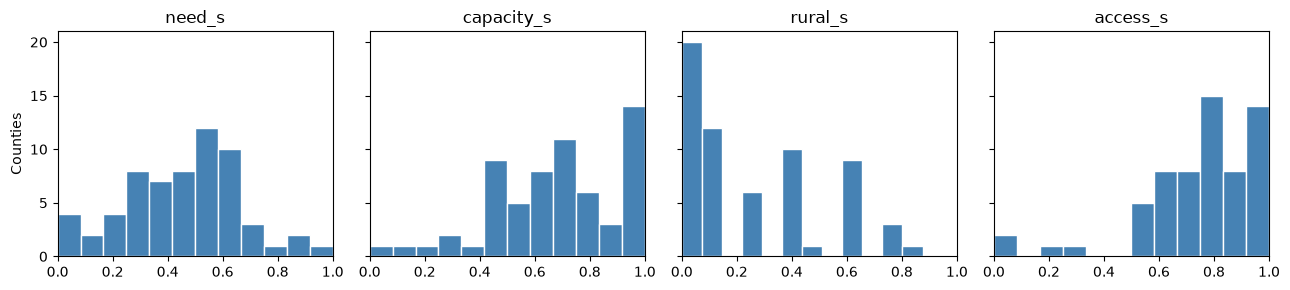

In [3]:
# Histograms of the four standardized criteria (shared y-axis for comparison).
fig, axes = plt.subplots(1, 4, figsize=(13, 3), sharey=True)  # four side-by-side panels
for ax, col in zip(axes, STD):
    ax.hist(counties[col], bins=12, color="steelblue", edgecolor="white")  # score distribution
    ax.set_title(col)  # criterion name
    ax.set_xlim(0, 1)  # standardized domain
axes[0].set_ylabel("Counties")  # shared count axis label
plt.tight_layout()  # tighten spacing
plt.show()  # render the figure



#### The outlier problem

Min-max scaling depends entirely on the two most extreme values. Manhattan's ICU-bed LQ (2.31) is far above the rest, which **compresses** the remaining counties into the upper part of the `capacity_s` scale. Distance has a similar long tail in the North Country.

**Percentile-rank normalization** avoids this problem by scoring each county by its *position* in the distribution rather than its distance from the extremes:

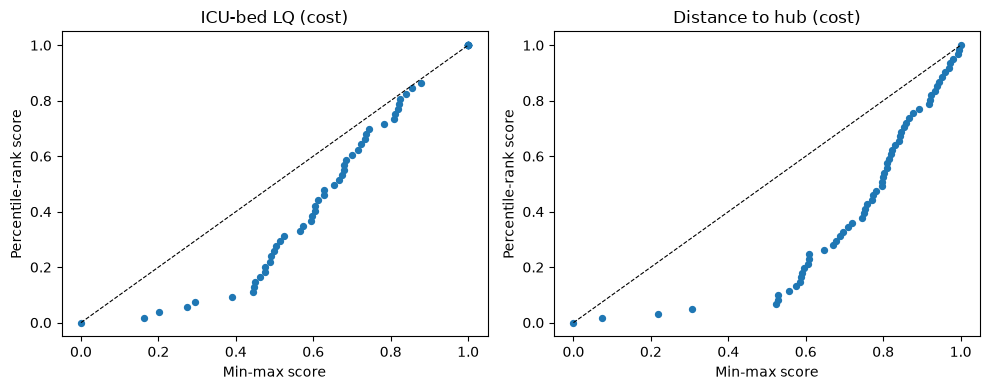

In [4]:
# Compare min-max vs percentile-rank normalisation for the two skewed cost criteria.
counties["capacity_r"] = percentile_rank_normalize(counties["icu_lq"], benefit=False)  # rank-based capacity
counties["access_r"] = percentile_rank_normalize(counties["hub_km"], benefit=False)  # rank-based access

fig, axes = plt.subplots(1, 2, figsize=(10, 4))  # two scatter panels
for ax, (mm, pr, name) in zip(axes, [("capacity_s", "capacity_r", "ICU-bed LQ (cost)"),
                                     ("access_s", "access_r", "Distance to hub (cost)")]):
    ax.scatter(counties[mm], counties[pr], s=18)  # each county as a point
    ax.plot([0, 1], [0, 1], "k--", lw=0.8)  # 1:1 reference line
    ax.set(xlabel="Min-max score", ylabel="Percentile-rank score", title=name)  # axis labels
plt.tight_layout()  # tighten spacing
plt.show()  # render the figure



Neither method is "correct":

- **Min-max** preserves the *magnitude* of differences. A county twice as far from a hub loses proportionally more.
- **Percentile rank** preserves only *order*. It is robust to outliers, but it treats a 1 km gap and a 50 km gap the same if they separate neighboring ranks.

The main analysis uses min-max scaling. Section 2.6 checks whether the choice changes the ranking.

### Assigning weights

The weights express the program's priorities and must sum to 1. They are set **before** looking at the results, which guards against tuning the weights to favor a preferred outcome.

| Criterion | Weight | Rationale |
|---|---|---|
| Need | 0.35 | The primary purpose of the clinic |
| Capacity gap | 0.25 | Targets under-served hospital markets |
| Rurality | 0.25 | Program eligibility focus |
| Referral access | 0.15 | Important, but telehealth reduces its role |

Module 6 replaces these direct-rating weights with the **Analytic Hierarchy Process (AHP)**.

In [5]:
# Assign expert weights (must sum to 1) and compute the WLC suitability score.
WEIGHTS = {"need_s": 0.35, "capacity_s": 0.25, "rural_s": 0.25, "access_s": 0.15}  # baseline weights
assert abs(sum(WEIGHTS.values()) - 1) < 1e-9, "Weights must sum to 1"  # sanity check

# Weighted linear combination of the standardized criteria.
counties["score"] = weighted_linear_combination({c: counties[c] for c in WEIGHTS}, WEIGHTS)  # WLC score
counties["rank"] = counties["score"].rank(ascending=False, method="min").astype(int)  # 1 = best

# Preview the top-ranked counties alongside raw criteria and the Boolean AND flag.
counties.sort_values("rank")[["rank", "county", "score", "need_index", "icu_lq",
                              "rucc", "hub_km", "suitable_and"]].head(12).round(3)  # top 12



,rank,county,score,need_index,icu_lq,rucc,hub_km,suitable_and
19,1,Hamilton County,0.841,128.299,0.000,8,112.624,False
48,2,Delaware County,0.839,132.549,0.000,6,56.284,True
18,3,Greene County,0.745,114.783,0.000,6,50.848,True
56,4,Schuyler County,0.714,114.212,0.000,6,94.241,True
0,5,Allegany County,0.703,119.851,0.639,7,99.249,True
61,6,Cattaraugus County,0.700,120.772,0.000,4,74.513,True
32,7,Seneca County,0.681,104.472,0.000,6,62.905,True
36,8,Chenango County,0.673,117.116,0.728,6,60.302,True
1,9,Columbia County,0.669,115.096,0.743,6,46.743,True
37,10,Essex County,0.667,114.026,0.000,6,163.428,False


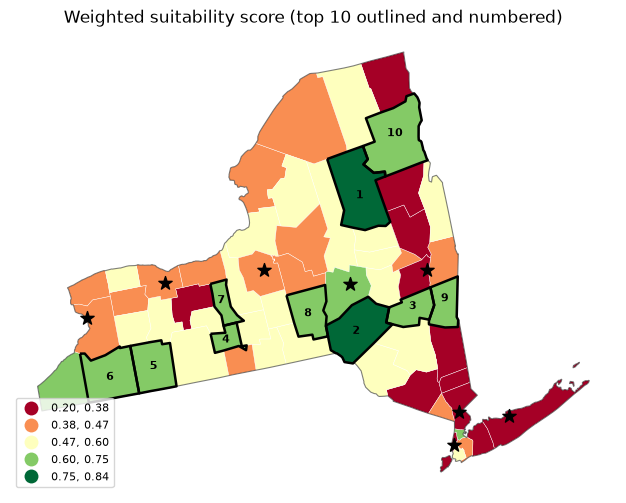

In [6]:
# Map the WLC score, outline the top 10 counties, and annotate their ranks.
ax = choropleth(counties, "score", "Weighted suitability score (WLC, min-max)")  # score surface
hubs.plot(ax=ax, marker="*", color="black", markersize=100)  # referral hubs
top10 = counties[counties["rank"] <= 10]  # top-ten subset
top10.boundary.plot(ax=ax, color="black", linewidth=1.8)  # bold outlines for top 10
# Annotate each top-10 county with its rank at a representative interior point.
for _, r in top10.iterrows():
    p = r.geometry.representative_point()  # label anchor inside the polygon
    ax.annotate(r["rank"], (p.x, p.y), ha="center", va="center", fontsize=8, fontweight="bold")  # rank label
ax.set_title("Weighted suitability score (top 10 outlined and numbered)")  # final title
plt.show()  # render the figure



### Why does a county score highly? Criterion contributions

Each county's score is a sum of weighted parts, $w_j x_{ij}$. Plotting those parts shows *why* a county ranks where it does. This makes the model transparent and easy to explain to stakeholders.

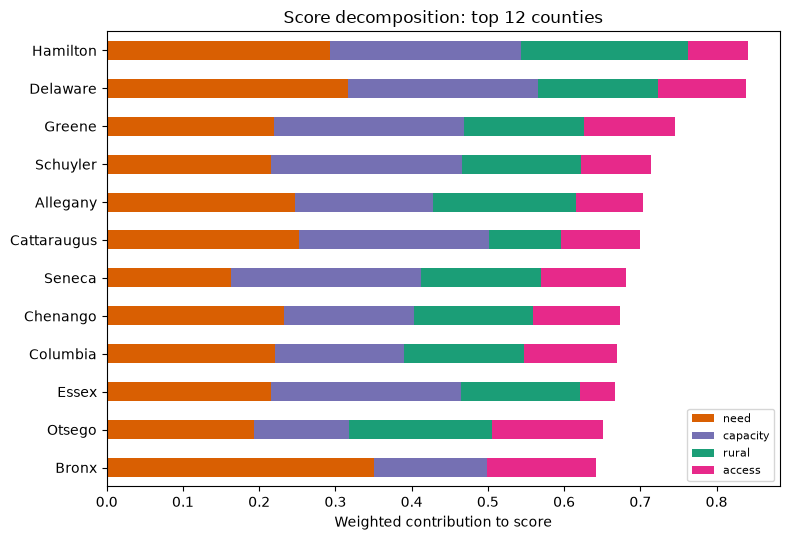

In [7]:
# Decompose each top-12 county's score into weighted criterion contributions.
contrib = pd.DataFrame({c.replace("_s", ""): counties[c] * w for c, w in WEIGHTS.items()})  # w_j * x_ij
contrib.index = counties["county"].str.replace(" County", "")  # shorter row labels
contrib = contrib.loc[counties.sort_values("rank")["county"].str.replace(" County", "").head(12)]  # top 12 order

# Stacked horizontal bars: each segment is one criterion's contribution.
ax = contrib.iloc[::-1].plot.barh(stacked=True, figsize=(8, 5.5),
                                  color=["#d95f02", "#7570b3", "#1b9e77", "#e7298a"])  # criterion colours
ax.set(xlabel="Weighted contribution to score", ylabel="",
       title="Score decomposition: top 12 counties")  # axis labels / title
ax.legend(loc="lower right", fontsize=8)  # criterion legend
plt.tight_layout()  # tighten spacing
plt.show()  # render the figure



### Categorical vs. weighted results

How well do the two approaches agree? The comparison below takes the 12 counties that passed the categorical screen and the top 12 by weighted score.

In [8]:
# Compare the Boolean AND set with the WLC top-12 set (agreement / disagreement).
cat_set = set(counties.loc[counties["suitable_and"], "county"])  # categorical suitable set
wlc_set = set(counties.nsmallest(12, "rank")["county"])  # weighted top-12 set

print(f"In both            ({len(cat_set & wlc_set)}):", sorted(cat_set & wlc_set))  # intersection
print(f"Categorical only   ({len(cat_set - wlc_set)}):", sorted(cat_set - wlc_set))  # Boolean only
print(f"Weighted top-12 only ({len(wlc_set - cat_set)}):", sorted(wlc_set - cat_set))  # WLC only



In both            (8): ['Allegany County', 'Cattaraugus County', 'Chenango County', 'Columbia County', 'Delaware County', 'Greene County', 'Schuyler County', 'Seneca County']
Categorical only   (4): ['Cayuga County', 'Fulton County', 'Montgomery County', 'Steuben County']
Weighted top-12 only (4): ['Bronx County', 'Essex County', 'Hamilton County', 'Otsego County']


In [9]:
# Inspect counties that enter the WLC top 12 without passing the categorical AND screen.
counties[counties["county"].isin(wlc_set - cat_set)][
    ["county", "rank", "score", "need_index", "icu_lq", "rucc", "hub_km"]].round(2)  # compensation cases



,county,rank,score,need_index,icu_lq,rucc,hub_km
19,Hamilton County,1,0.84,128.30,0.00,8,112.62
37,Essex County,10,0.67,114.03,0.00,6,163.43
40,Otsego County,11,0.65,110.09,1.16,7,11.24
45,Bronx County,12,0.64,138.69,0.93,1,15.53


Counties that enter the weighted top 12 without passing the categorical screen are the **compensation effect** in action. Each fails one threshold: distance to a hub for Hamilton and Essex, ICU capacity for Otsego, and rurality for the Bronx. Each is strong enough on the other criteria to rank highly anyway. The Bronx, a fully metropolitan county, reaches the top 12 on need alone. Whether that is acceptable is a **policy question**, not a technical one. If the 100 km referral limit is non-negotiable, it should be a constraint rather than a weighted factor.

### Hybrid model: constraints + weighted ranking

Most real suitability models are hybrids:

1. **Hard constraints** (Boolean) remove infeasible locations.
2. **Soft factors** (weighted) rank the locations that remain.

In this example, eligibility (non-metro) and the referral limit (≤ 100 km) are treated as constraints, while need, capacity, and rurality are weighted factors.

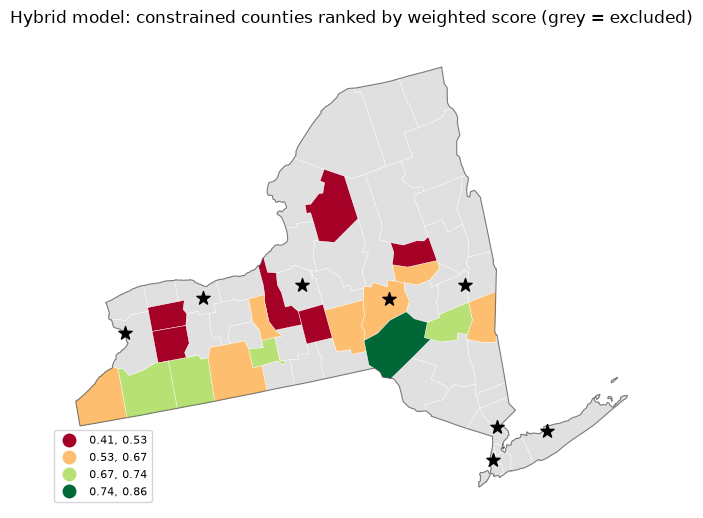

,county,score_hybrid,need_index,icu_lq,rucc,hub_km
48,Delaware County,0.863,132.549,0.000,6,56.284
18,Greene County,0.738,114.783,0.000,6,50.848
56,Schuyler County,0.734,114.212,0.000,6,94.241
0,Allegany County,0.722,119.851,0.639,7,99.249
61,Cattaraugus County,0.718,120.772,0.000,4,74.513
32,Seneca County,0.666,104.472,0.000,6,62.905
36,Chenango County,0.660,117.116,0.728,6,60.302
1,Columbia County,0.644,115.096,0.743,6,46.743


In [10]:
# Hybrid model: hard Boolean constraints, then WLC ranking among feasible counties.
constraint = counties["ok_rural"] & counties["ok_access"]  # must be non-metro and within 100 km

HYBRID_W = {"need_s": 0.45, "capacity_s": 0.30, "rural_s": 0.25}  # weights among constrained counties
# Score unconstrained counties as NaN/masked via hybrid_suitability.
counties["score_hybrid"] = hybrid_suitability(
    weighted_linear_combination({c: counties[c] for c in HYBRID_W}, HYBRID_W),  # WLC among hybrid weights
    constraint,  # Boolean mask of feasible counties
)

# Grey out excluded counties; colour constrained counties by hybrid score.
ax = counties.plot(color="#e0e0e0", edgecolor="white", linewidth=0.3)  # excluded = grey base
counties[constraint].plot("score_hybrid", ax=ax, cmap="RdYlGn", scheme="naturalbreaks", k=4,
                          legend=True, edgecolor="white", linewidth=0.3,  # feasible counties
                          legend_kwds={"loc": "lower left", "fontsize": 8})  # legend
state.boundary.plot(ax=ax, color="#00000080", linewidth=0.8)  # state outline
hubs.plot(ax=ax, marker="*", color="black", markersize=100)  # hubs
ax.set_title("Hybrid model: constrained counties ranked by weighted score (grey = excluded)")  # title
ax.set_axis_off()  # hide axis ticks
plt.show()  # render the figure

# Preview the top hybrid-ranked feasible counties.
(counties[constraint].sort_values("score_hybrid", ascending=False)
    [["county", "score_hybrid", "need_index", "icu_lq", "rucc", "hub_km"]].head(8).round(3))  # top 8



### Is the ranking robust?

Weights and normalization choices are judgments, so a credible analysis shows how much the results depend on them. The analysis below compares four weighting scenarios and the alternative normalization, using **Spearman's rank correlation** with the baseline and the **rank range** of the leading counties.

In [11]:
# Rank stability across weight scenarios and an alternate normalisation choice.
scenarios = {
    "Baseline":        WEIGHTS,  # original expert weights
    "Equal weights":   {"need_s": .25, "capacity_s": .25, "rural_s": .25, "access_s": .25},  # uniform
    "Need-focused":    {"need_s": .55, "capacity_s": .15, "rural_s": .15, "access_s": .15},  # emphasise need
    "Access-focused":  {"need_s": .25, "capacity_s": .20, "rural_s": .20, "access_s": .35},  # emphasise access
}

ranks = pd.DataFrame(index=counties["county"])  # one column per scenario
for name, w in scenarios.items():
    # Rank counties under this weight vector (1 = best score).
    ranks[name] = pd.Series(weighted_linear_combination({c: counties[c] for c in w}, w), index=counties.index).rank(ascending=False, method="min").values  # scenario ranks

# Alternative normalisation: swap in percentile-rank versions of the two cost criteria.
alt = counties.assign(capacity_s=counties["capacity_r"], access_s=counties["access_r"])  # replace columns
ranks["Pct-rank normalization"] = pd.Series(weighted_linear_combination({c: alt[c] for c in WEIGHTS}, WEIGHTS), index=alt.index).rank(ascending=False, method="min").values  # alt ranks

ranks.corr(method="spearman")["Baseline"].round(3).to_frame("Spearman rho vs baseline")  # rank agreement



,Spearman rho vs baseline
Baseline,1.000
Equal weights,0.973
Need-focused,0.951
Access-focused,0.898
Pct-rank normalization,0.969


In [12]:
# Best/worst rank range for the baseline top-12 counties across all scenarios.
top = ranks.sort_values("Baseline").head(12).astype(int)  # baseline top 12 with integer ranks
top["Best"] = top.min(axis=1)  # best (lowest) rank across scenarios
top["Worst"] = top.drop(columns="Best").max(axis=1)  # worst (highest) rank across scenarios
top  # display the rank-range table



,Baseline,Equal weights,Need-focused,Access-focused,Pct-rank normalization,Best,Worst
county,,,,,,,
Hamilton County,1,2,2,2,2,1,2
Delaware County,2,1,1,1,1,1,2
Greene County,3,3,4,3,3,3,4
Schuyler County,4,4,8,10,4,4,10
Allegany County,5,8,6,11,8,5,11
Cattaraugus County,6,6,5,8,5,5,8
Seneca County,7,5,14,7,7,5,14
Chenango County,8,10,9,9,10,8,10
Columbia County,9,9,10,5,9,5,10


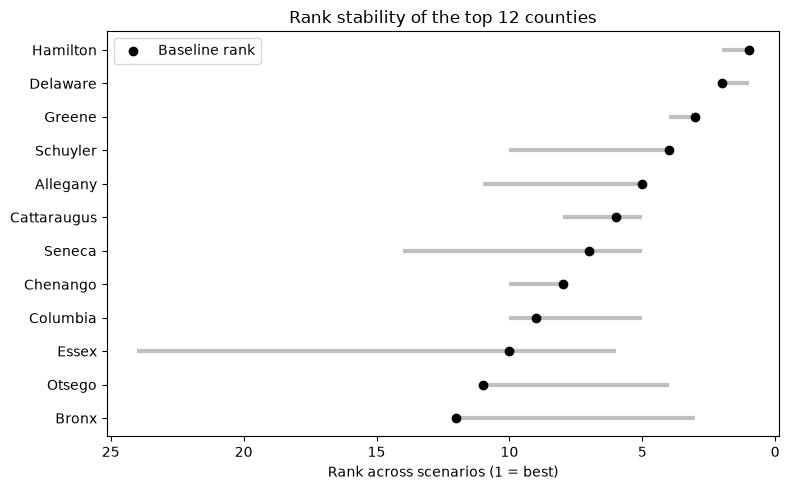

In [13]:
# Rank-range plot: horizontal span from best to worst scenario rank for each top-12 county.
fig, ax = plt.subplots(figsize=(8, 5))  # figure for the stability plot
t = top.iloc[::-1]  # reverse so best baseline county is at the top
names = t.index.str.replace(" County", "")  # shorter y labels
ax.hlines(names, t["Best"], t["Worst"], color="grey", lw=3, alpha=0.5)  # best-worst span
ax.scatter(t["Baseline"], names, color="black", zorder=3, label="Baseline rank")  # baseline markers
ax.set(xlabel="Rank across scenarios (1 = best)", title="Rank stability of the top 12 counties")  # labels
ax.invert_xaxis()  # put rank 1 on the right for a natural "better" direction
ax.legend()  # show baseline legend
plt.tight_layout()  # tighten spacing
plt.show()  # render the figure



High Spearman correlations (above about 0.9) mean the **overall pattern is stable**. The rank-range plot is more useful for decisions: counties with **short bars near rank 1** are robust recommendations, while counties whose rank swings widely depend heavily on the weighting.

Part III extends this analysis to **Monte Carlo weight simulation** and **global sensitivity analysis**.

### Export results

In [14]:
# Export the weighted scores, ranks, and hybrid score to GeoPackage and CSV.
cols = ["GEOID", "county", "pop", "need_index", "icu_lq", "rucc", "hub_km", "nearest_hub",
        "suitable_and", "n_met", "need_s", "capacity_s", "rural_s", "access_s",
        "score", "rank", "score_hybrid"]  # columns to retain

counties[cols + ["geometry"]].to_file(str(DATA_DIR / "ny_weighted_suitability.gpkg"),
                                      layer="counties", driver="GPKG")  # spatial export
counties[cols].sort_values("rank").to_csv(str(DATA_DIR / "ny_suitability_ranking.csv"), index=False)  # CSV ranking
print("Saved GeoPackage and CSV ranking.")  # confirm exports



Saved GeoPackage and CSV ranking.


## Exercises

1. Replace min-max with **z-score** standardization followed by a logistic transform. Does the top 10 change?
2. Move access from a weighted factor to a hard constraint at 150 km and recompute. Which approach better reflects the program goal?
3. Write a function that takes a weight dictionary and returns the top *k* counties. Find a set of weights under which **Chautauqua County** ranks first. Is that set of weights defensible?
4. Add a fifth criterion, such as the unemployment rate from the Module 1 raw table, and assign weights. How do you rebalance the existing weights?

## Key takeaways

- WLC computes $S = \sum w_j x_j$ on standardized criteria, and it is **compensatory**.
- Standardization must account for direction (**benefit or cost**), and min-max scaling is **sensitive to outliers**.
- **Score decomposition** makes the model transparent.
- **Hybrid models** (constraints + weighted factors) usually reflect real decision rules best.
- Always report how **robust** the ranking is to weights and normalization choices.

---

## Part I summary and what comes next

| Module | Topic | Main method |
|---|---|---|
| 1 | Criteria data | Attribute join, reprojection, choropleths |
| 2 | Deriving criteria | Relative indices, location quotient, spatial join, `sjoin_nearest` |
| 3 | Categorical suitability | Boolean AND/OR, k-of-n, threshold sensitivity |
| 4 | Weighted suitability | Min-max and rank normalization, WLC, hybrid model, weight sensitivity |

**Part II: Raster-Based Suitability** moves from counties to a continuous surface. It covers DEM-derived slope, Euclidean distance rasters, constraint masks, *Rescale by Function*, and Python equivalents of ArcGIS **Weighted Overlay** and **Weighted Sum**.